In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [27]:
bean_dataset = pd.read_csv('dry_bean.csv')
print('Dataset shape:', bean_dataset.shape)
print(bean_dataset.head())

Dataset shape: (13611, 17)
    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395    610.291       208.178117       173.888747      1.197191   
1  28734    638.018       200.524796       182.734419      1.097356   
2  29380    624.110       212.826130       175.931143      1.209713   
3  30008    645.884       210.557999       182.516516      1.153638   
4  30140    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272750  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0  

In [28]:
features = [col for col in bean_dataset.columns if col != 'Class']
print('Number of features:', len(features))
print('Feature names:', features)
print(bean_dataset['Class'].value_counts())

Number of features: 16
Feature names: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


In [29]:
raw_features = bean_dataset[features]
x = StandardScaler().fit_transform(raw_features)
print('Standardized data shape:', x.shape)

Standardized data shape: (13611, 16)


In [30]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x)
pca_df = pd.DataFrame(principal_components, columns=['PC1', 'PC2'])
print(pca_df.head())

        PC1       PC2
0 -4.981561  1.824697
1 -5.436792  2.932365
2 -4.758088  1.826884
3 -4.300541  2.003661
4 -6.349340  4.088205


In [31]:
pc1_var, pc2_var = pca.explained_variance_ratio_
print('PC1: {:.1%}'.format(pc1_var))
print('PC2: {:.1%}'.format(pc2_var))
print('Total: {:.1%}'.format(pc1_var + pc2_var))

PC1: 55.5%
PC2: 26.4%
Total: 81.9%


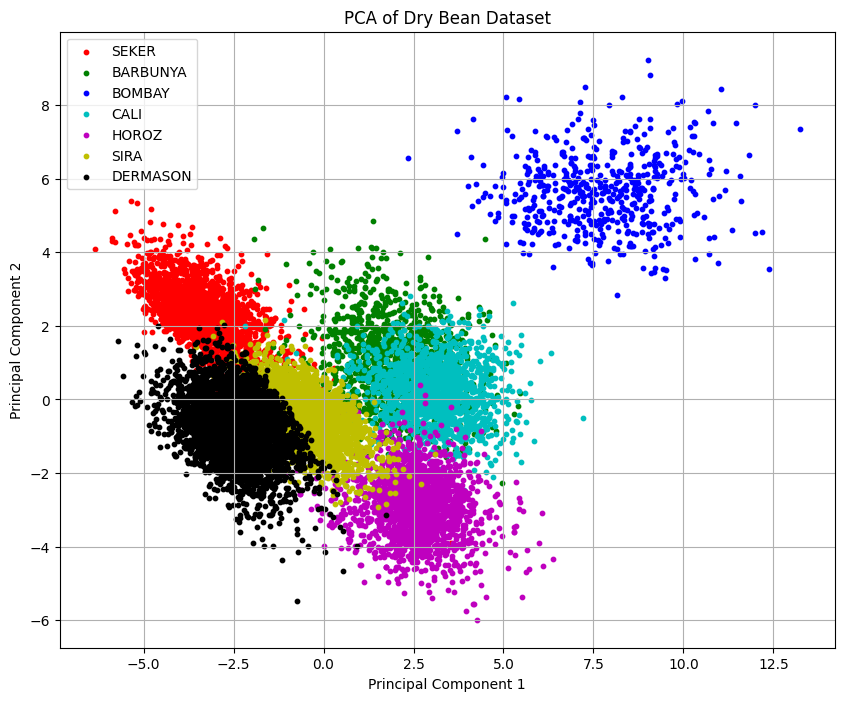

In [32]:
plt.figure(figsize=(10, 8))
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'k']
targets = ['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
for target, color in zip(targets, colors):
    mask = bean_dataset['Class'] == target
    plt.scatter(pca_df.loc[mask, 'PC1'], pca_df.loc[mask, 'PC2'], c=color, s=10, label=target)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Dry Bean Dataset')
plt.legend()
plt.grid()
plt.show()

Explanation (simple English)
I used PCA on the Dry Bean Dataset. The data has 16 features and seven bean types. I used StandardScaler and reduced the 16 features to two principal components. PC1 explains 55.5% of the variance, and PC2 explains 26.4%. Together, they explain 81.9% of the variance. The graph shows the bean types in two dimensions. Some groups may overlap. PCA reduces dimensions; it does not classify the beans.

**Dataset Source**

UCI Machine Learning Repository – Dry Bean Dataset

https://archive.ics.uci.edu/dataset/602/dry+bean+dataset